# QAOA on Max-Cut (primer)

*Part of milestone 3 · borrowed from UTC's problem set (Problem 2)*

Max-Cut is the textbook QAOA problem: split a small grid's substations into two groups so that as many lines as possible run between the groups. (It's only a practice problem. Real grid islanding is closer to the opposite: cut as few lines as possible.) It shows QAOA's three pieces, which you'll meet again in plant scheduling: a cost layer, a mixer, and a classical optimizer that tunes them.

**Your job (about 45 minutes):** fill in the cost layer and the optimizer loop, solve the 6-node grid, and compare it with the brute-force best. The 12-node scale-up is optional.

> **Before you run anything, pick the kernel.** When this notebook opens, a **Select Kernel** box appears with *Python 3 (ipykernel)* already selected. That's the wrong one: change it to **qBraid-SDK (v0.12.2)**, then click **Select**. Picked the wrong one, or closed the box? Click the kernel name at the top right of the notebook and choose **qBraid-SDK (v0.12.2)**. The first cell checks, and tells you if it's wrong.

In [ ]:
# Resolve data and shared helpers when opening a notebook from its own folder.
from pathlib import Path
import os
import sys
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/check.py').is_file() and (p / 'data').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook inside the cloned project.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
os.chdir(PROJECT_ROOT)


In [1]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no job and no credits. The first run installs it (a few seconds), pinned to the version tested here.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    %pip install -q qiskit-aer==0.18.2

import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from scipy.optimize import minimize

sim = AerSimulator()

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


In [2]:
# The grids (nodes are substations, edges are power lines)

# 6-node grid (2 x 3) for Part 1
edges_small = [(0,1),(1,2),(3,4),(4,5),(0,3),(1,4),(2,5)]
n_small = 6

# 12-node grid (3 x 4) for the GPU scale-up in Part 2
edges_large = [(0,1),(1,2),(2,3),(4,5),(5,6),(6,7),(8,9),(9,10),(10,11),
               (0,4),(4,8),(1,5),(5,9),(2,6),(6,10),(3,7),(7,11)]
n_large = 12

n, edges = n_small, edges_small    # Part 1 uses the 6-node grid; the scale-up cell switches to 12


In [3]:
def cut_value(bitstring, edges):
    """Count how many edges are cut by a 0/1 assignment (given as a string)."""
    bits = [int(b) for b in bitstring]
    return sum(1 for (u, v) in edges if bits[u] != bits[v])


In [4]:
def qaoa_circuit(params, n, edges, p):
    """Max-Cut cost rotations, X mixers, then measurement (node i = qubit i)."""
    gammas, betas = params[:p], params[p:]
    qc = QuantumCircuit(n, n)
    qc.h(range(n))
    for layer in range(p):
        # ZZ phase for each edge: the starter's angle convention is 2*gamma.
        # Max-Cut and unit commitment use the same cost/mixer structure,
        # but encode different objectives in their cost Hamiltonians.
        for u, v in edges:
            qc.cx(u, v)
            qc.rz(2 * gammas[layer], v)
            qc.cx(u, v)
        for q in range(n):
            qc.rx(2 * betas[layer], q)
    qc.measure(range(n), range(n))
    return qc


In [5]:
PRIMER_TRAIN_SEED = 41
PRIMER_READOUT_SEED = 1041  # independent final samples; not used for selection
PRIMER_TRAIN_SHOTS = 512
PRIMER_FINAL_SHOTS = 2048
primer_objective_calls = 0

def expected_cut(params, n, edges, p, shots=PRIMER_TRAIN_SHOTS):
    """Sampled average cut; reproducible training randomness, not an exact expectation."""
    global primer_objective_calls
    primer_objective_calls += 1
    qc = qaoa_circuit(params, n, edges, p)
    counts = sim.run(transpile(qc, sim, seed_transpiler=41), shots=shots,
                     seed_simulator=PRIMER_TRAIN_SEED).result().get_counts()
    return sum(cut_value(bs[::-1], edges) * c for bs, c in counts.items()) / sum(counts.values())


In [6]:
# Three predeclared starts; choose by training objective, never by final readout.
import time
p = 1
primer_objective_calls = 0
primer_started = time.perf_counter()
primer_rng = np.random.default_rng(41)
primer_restarts = []

def objective(params):
    return -expected_cut(params, n, edges, p)

for restart in range(3):
    x0 = primer_rng.uniform(0, np.pi, 2*p)
    fit = minimize(objective, x0, method="COBYLA",
                   options={"maxiter":80, "rhobeg":0.4})
    primer_restarts.append(fit)
    print(f"Restart {restart}: training mean cut {-fit.fun:.4f}, {fit.nfev} evaluations")
result = min(primer_restarts, key=lambda fit: fit.fun)
primer_training_seconds = time.perf_counter() - primer_started
print(f"Selected by training mean. Total evaluations: {primer_objective_calls}; "
      f"training shots: {primer_objective_calls * PRIMER_TRAIN_SHOTS}; "
      f"local training time: {primer_training_seconds:.3f} s")


Restart 0: training mean cut 5.0801, 32 evaluations


Restart 1: training mean cut 5.0820, 27 evaluations


Restart 2: training mean cut 5.0664, 28 evaluations
Selected by training mean. Total evaluations: 87; training shots: 44544; local training time: 8.090 s


In [7]:
# Read out the best partition (run after the optimizer works)
best_params = result.x
qc = qaoa_circuit(best_params, n, edges, p)
counts = sim.run(transpile(qc, sim), shots=PRIMER_FINAL_SHOTS, seed_simulator=PRIMER_READOUT_SEED).result().get_counts()
# Of the bitstrings QAOA sampled, keep the one with the biggest cut.
# Qiskit lists qubit 0 last, so reverse each bitstring to match node order.
best_bits = max((bs[::-1] for bs in counts), key=lambda b: cut_value(b, edges))
group_A = [i for i, b in enumerate(best_bits) if b == '0']
group_B = [i for i, b in enumerate(best_bits) if b == '1']
print("Group A:", group_A)
print("Group B:", group_B)
print("Cut value:", cut_value(best_bits, edges), "(compare with the brute-force best below)")
# On a grid this small, the best of 2,048 samples finds the best cut even by random guessing.
# So also compare the AVERAGE cut per shot with random guessing, which cuts each line half the time.
avg = sum(cut_value(bs[::-1], edges) * c for bs, c in counts.items()) / sum(counts.values())
print(f"Average cut per shot: {avg:.2f}   random guessing: {len(edges) / 2:.1f}")

Group A: [0, 2, 4]
Group B: [1, 3, 5]
Cut value: 7 (compare with the brute-force best below)
Average cut per shot: 5.00   random guessing: 3.5


In [8]:
# Classical baseline (brute force), provided. Fine up to about 20 nodes.
from itertools import product
def brute_force(n, edges):
    best_cut, best = -1, None
    for assign in product([0,1], repeat=n):
        c = cut_value("".join(map(str, assign)), edges)
        if c > best_cut:
            best_cut, best = c, assign
    return best_cut, best
print(f"Best possible cut (classical, {n} nodes):", brute_force(n, edges)[0])


Best possible cut (classical, 6 nodes): 7


## Milestone 3 — connection to plant scheduling

**Both Max-Cut and plant scheduling encode binary choices in a cost Hamiltonian: QAOA alternates cost-dependent phase rotations with mixer rotations, while a classical optimizer tunes the angles.** Max-Cut rewards edges joining opposite groups; our plant QUBO minimizes estimated operating costs plus constraint penalties and uses slack bits for reserve.

The cost layer changes phases, the mixer redistributes amplitudes, and the optimizer searches for angles that improve the measured objective. Our plant checker then evaluates feasibility and economic dispatch classically. Completing Max-Cut does not prove that the plant cost approximation is exact for every dataset or that QAOA beats MILP.

This six-node grid is bipartite: its alternating partition cuts all seven edges, proving the classical optimum is seven. The average cut per shot is more informative than the best of 2,048 draws, because random sampling can also find a perfect partition on such a small graph. Training uses three starts and 512 shots per evaluation; the final comparison uses independent measurement draws. Those training costs are additional to final shots.


Classical optimum: 7; QAOA best sampled: 7; random best sampled: 7
Independent final means: QAOA 4.9980, random 3.5186; uniform theoretical mean 3.5000
A best sampled optimum is not evidence of speedup; report the means and training work.


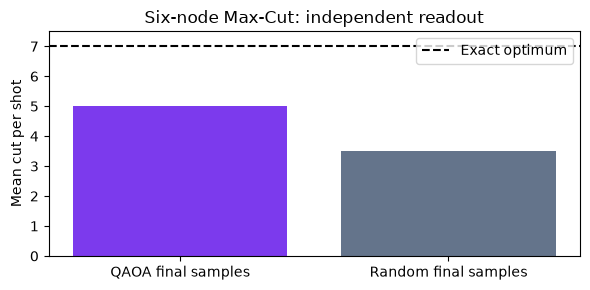

In [9]:
# Independent final random control, with the same final-shot budget.
random_bits = np.random.default_rng(2041).integers(0, 2, (PRIMER_FINAL_SHOTS, n))
random_cuts = np.array([sum(bits[u] != bits[v] for u,v in edges) for bits in random_bits])
optimal_cut = brute_force(n, edges)[0]
sampled_cut = cut_value(best_bits, edges)
assert sampled_cut <= optimal_cut
assert optimal_cut == len(edges)  # all edges can be cut in this bipartite grid
print(f"Classical optimum: {optimal_cut}; QAOA best sampled: {sampled_cut}; "
      f"random best sampled: {random_cuts.max()}")
print(f"Independent final means: QAOA {avg:.4f}, random {random_cuts.mean():.4f}; "
      f"uniform theoretical mean {len(edges)/2:.4f}")
print("A best sampled optimum is not evidence of speedup; report the means and training work.")
fig, ax = plt.subplots(figsize=(6,3))
ax.bar(['QAOA final samples', 'Random final samples'], [avg, random_cuts.mean()],
       color=['#7c3aed','#64748b'])
ax.axhline(optimal_cut, color='black', linestyle='--', label='Exact optimum')
ax.set(ylabel='Mean cut per shot', ylim=(0,optimal_cut+0.5), title='Six-node Max-Cut: independent readout')
ax.legend(); fig.tight_layout(); plt.show()


### Optional: 12-node scale-up (Part 2)

UTC asks you to run a bigger grid on qBraid's GPU simulator and note how the runtime changes. Two steps:

1. Run the next cell to switch to the 12-node grid, then re-run the optimizer and read-out cells above. Keep tuning on Aer: the optimizer runs the circuit dozens of times, and 12 qubits still takes seconds here.
2. Then run the cell after it. It sends your tuned circuit to qBraid's GPU simulator (an NVIDIA GH200) and times it against Aer.

In [ ]:
# Step 1: switch to the 12-node grid, then re-run the optimizer and read-out cells above
n, edges = n_large, edges_large
print(f"Now on the {n}-node grid ({len(edges)} lines). Re-run the optimizer and read-out cells, then run the next cell.")

In [ ]:
# Step 2 (optional): run your tuned circuit on qBraid's GPU simulator and time it against Aer.
# Free up to a daily limit of runs, then 5 credits a minute of run time. Set this to True to send it:
RUN_ON_GPU = False

import time
qc = qaoa_circuit(result.x, n, edges, p)
t0 = time.time()
aer_counts = sim.run(transpile(qc, sim), shots=2048).result().get_counts()
aer_secs = time.time() - t0

if RUN_ON_GPU:
    from qbraid.runtime import QbraidProvider
    device = QbraidProvider().get_device("qbraid:qbraid:sim:gpu-sv")
    t0 = time.time()
    job = device.run(qc, shots=2048)
    gpu_counts = job.result().data.get_counts()
    gpu_secs = time.time() - t0
    print("Job ID:", job.id)          # copy this into your write-up
    for name, c in [("Aer, here", aer_counts), ("qBraid GPU simulator", gpu_counts)]:
        avg = sum(cut_value(bs[::-1], edges) * k for bs, k in c.items()) / sum(c.values())
        print(f"{name}: average cut per shot {avg:.2f}")
    print(f"{n} qubits, 2,048 shots: Aer took {aer_secs:.2f} s here; the GPU run took {gpu_secs:.0f} s, round trip included")
else:
    print(f"Aer ran the {n}-qubit circuit (2,048 shots) in {aer_secs:.2f} s. Set RUN_ON_GPU = True to compare with qBraid's GPU simulator.")

# When does a GPU pay off? Each extra qubit doubles the memory a state-vector simulator needs:
# Aer on a 4 GB Lab instance runs out at about 28 qubits, and qBraid's GPU simulator goes to 35.

## What to have ready (milestone 3)
- The 6-node partition and its cut value, next to the brute-force best.
- Your average cut per shot next to random guessing (half the lines), and why the average is the fairer measure here. (Can you find a best partition just by looking at the grid? How do you know it's best?)
- One sentence for your deck: what the cost layer, the mixer and the optimizer each do, and how the Max-Cut cost relates to your track's cost function.
- Optional: the 12-node result (Part 2), with Aer's time next to the GPU simulator's, and what that says about when a GPU pays off.